# Parts B and C: Synthetic data and simulated analysis
4페이지 보고서 순서: 데이터 생성 → 그림과 가정 점검 → Welch 검정 → 반복 시뮬레이션 → 해석.
A의 네 곡별 점수를 따로 만들지 않고, 참가자의 최종 평균 선호도를 직접 생성합니다.
각 참가자는 한 집단에만 속하며 한 개의 분석값을 제공합니다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
SIM_SEED = 20260929
N_GROUP = 60
BASE_MEAN = 55
SD = 15  # 참가자별 평균 점수 사이의 표준편차
ALPHA = 0.05
N_REPS = 5000
OUTPUT_DIR = Path(__file__).resolve().parent / 'outputs' if '__file__' in globals() else Path.cwd() / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. 두 데이터셋 생성 — 보고서 B
WorkB의 생성 순서와 설정을 유지합니다. 효과는 10점 또는 0점이며, 점수는 0–100으로 제한합니다.
예시 두 개에 같은 seed를 사용해 특성·배정·잡음을 같게 하고 효과만 비교합니다.

In [2]:
def simulate_data(effect_size, seed):
    rng = np.random.default_rng(seed)
    n = N_GROUP * 2
    # 네 취향 특성은 각각 독립 생성하며, 이 모형에서는 점수에 별도 영향을 주지 않습니다.
    data = pd.DataFrame({
        'pitch': rng.choice(['low', 'high'], n),
        'tempo': rng.choice(['slow', 'fast'], n),
        'beat': rng.choice(['weak', 'strong'], n),
        'mode': rng.choice(['minor', 'major'], n),
    })
    data['condition'] = rng.permutation(['matched'] * N_GROUP + ['mismatched'] * N_GROUP)
    means = BASE_MEAN + effect_size * (data['condition'] == 'matched').astype(int)
    data['liking'] = np.clip(rng.normal(loc=means, scale=SD, size=n), 0, 100)
    return data


def get_groups(data):
    """평균 차이의 방향을 맞추기 위해 matched, mismatched 순서로 반환합니다."""
    return tuple(data.loc[data['condition'] == c, 'liking'].to_numpy()
                 for c in ['matched', 'mismatched'])


data_effect = simulate_data(10, SEED)
data_null = simulate_data(0, SEED)
datasets = {'Effect present': data_effect, 'No effect': data_null}
for label, data in datasets.items():
    print(label)
    display(data.groupby('condition')['liking'].agg(['count', 'mean', 'std', 'min', 'max']).round(2))
data_effect.to_csv(OUTPUT_DIR / 'single_effect.csv', index=False)
data_null.to_csv(OUTPUT_DIR / 'single_null.csv', index=False)

Effect present


,count,mean,std,min,max
condition,,,,,
matched,60,65.91,16.34,30.00,99.91
mismatched,60,54.79,13.93,20.35,79.06


No effect


,count,mean,std,min,max
condition,,,,,
matched,60,55.91,16.34,20.00,89.91
mismatched,60,54.79,13.93,20.35,79.06


## 2. 데이터 시각화와 가정 점검 — 보고서 그림 1·2
Boxplot에서 두 집단의 위치·퍼짐·극단값을, Q–Q plot에서 정규분포로부터의 이탈을 살핍니다.
독립성은 한 참가자당 하나의 결과를 독립 생성한 설계에 근거합니다.

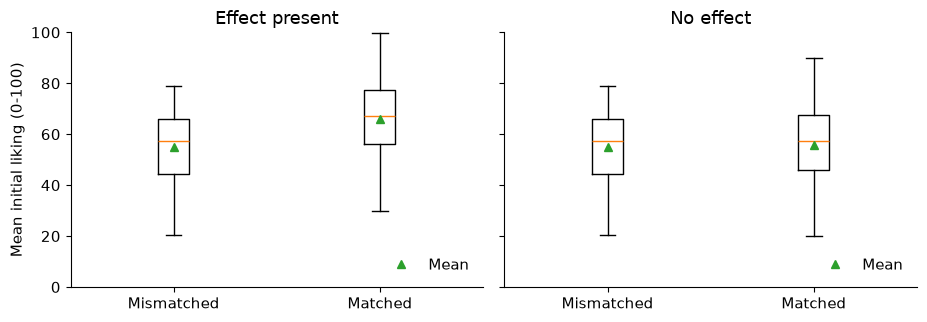

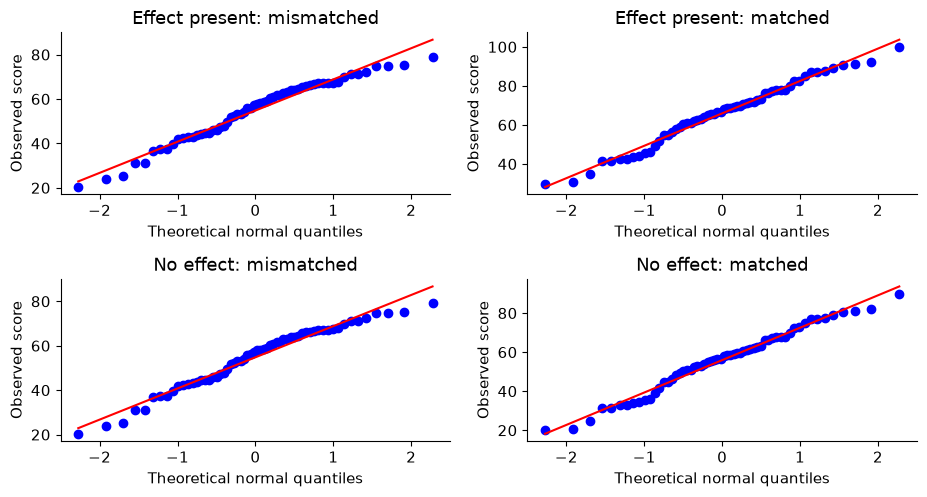

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.35), sharey=True)
for ax, (label, data) in zip(axes, datasets.items()):
    matched, mismatched = get_groups(data)
    box = ax.boxplot([mismatched, matched], showmeans=True)
    ax.set_xticks([1, 2], ['Mismatched', 'Matched'])
    ax.set(title=label, ylim=(0, 100))
    ax.legend([box['means'][0]], ['Mean'], frameon=False, loc='lower right')
axes[0].set_ylabel('Mean initial liking (0-100)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'report_datasets.png', dpi=220)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(9.4, 5.1))
for row, (label, data) in enumerate(datasets.items()):
    matched, mismatched = get_groups(data)
    for col, (group, scores) in enumerate([('mismatched', mismatched), ('matched', matched)]):
        ax = axes[row, col]
        stats.probplot(scores, plot=ax)
        ax.set(title=f'{label}: {group}', xlabel='Theoretical normal quantiles', ylabel='Observed score')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'report_qq.png', dpi=220)
plt.show()

기본 seed에서는 점들이 대체로 직선을 따르고, mismatched 집단의 꼬리에 일부 이탈이 있습니다.
뚜렷한 이상치나 0/100점은 없으며, 집단 SD는 13.93점과 16.34점입니다.
이 점검이 가정을 증명하지는 않습니다. 변환·관측값 제거 없이 양측 Welch t-test를 일관되게 사용합니다.
A의 조건부 Welch 선택을 고정된 분석으로 구체화한 것으로, 같은 데이터에서 유의한 방법을 골라 쓰지 않습니다.

## 3. 두 데이터셋의 Welch 검정 — 보고서 표 2
서로 다른 두 집단의 평균을 비교하며 등분산은 요구하지 않습니다. 유의수준은 .05입니다.
평균 차이(matched − mismatched), p값, 95% 신뢰구간을 SciPy로 계산합니다.

In [4]:
def analyse_data(data):
    matched, mismatched = get_groups(data)
    result = stats.ttest_ind(matched, mismatched, equal_var=False, alternative='two-sided')
    interval = result.confidence_interval(confidence_level=1 - ALPHA)
    return {'difference': matched.mean() - mismatched.mean(), 'p_value': result.pvalue,
            'ci_low': interval.low, 'ci_high': interval.high,
            'reject': bool(result.pvalue < ALPHA)}


single_results = pd.DataFrame({label: analyse_data(data) for label, data in datasets.items()}).T
display(single_results)
single_results.to_csv(OUTPUT_DIR / 'single_results.csv', index_label='scenario')

,difference,p_value,ci_low,ci_high,reject
Effect present,11.120504,0.000108,5.628334,16.612673,True
No effect,1.120504,0.686877,-4.371666,6.612673,False


기본 결과: 효과 있음은 11.12점 차이(p≈.000108), 효과 없음은 1.12점 차이(p≈.687)입니다.
효과를 넣은 경우에는 유의한 차이를 발견하지만, 유의하지 않은 결과가 무효과를 입증하지는 않습니다.
표집 변동으로 추정값은 설정값과 달라집니다. 점수 제한도 모집단 평균 차이를 조금 바꿀 수 있습니다.

## 4. H0·H1에서 각각 5,000회 반복 — 보고서 C
매번 새 데이터를 만들고 같은 검정을 수행합니다. 연구마다 별도 난수 스트림을 사용해 결과를 재현합니다.

In [5]:
def run_simulation(effect_size, seed):
    results = []
    for child_seed in seed.spawn(N_REPS):
        result = analyse_data(simulate_data(effect_size, child_seed))
        results.append(result)
    return pd.DataFrame(results)


null_seed, effect_seed = np.random.SeedSequence(SIM_SEED).spawn(2)
null_runs = run_simulation(0, null_seed)
effect_runs = run_simulation(10, effect_seed)
null_runs.to_csv(OUTPUT_DIR / 'simulation_null.csv', index=False)
effect_runs.to_csv(OUTPUT_DIR / 'simulation_effect.csv', index=False)

## 5. 오류율·검정력과 효과 추정치 — 보고서 표 3
제1종 오류율: H0에서 유의한 비율. 검정력: H1에서 유의한 비율. 제2종 오류율: 1 − 검정력.
효과 추정치의 평균과 SD는 연구 결과의 중심과 연구 간 변동을 나타냅니다.

In [6]:
type1 = null_runs['reject'].mean()
power = effect_runs['reject'].mean()
type2 = 1 - power
rates = pd.DataFrame({'metric': ['Type I error', 'Type II error', 'Power'],
                      'estimate': [type1, type2, power], 'studies': N_REPS})
display(rates)
rates.to_csv(OUTPUT_DIR / 'error_rates.csv', index=False)

effect_summary = pd.DataFrame([
    {'scenario': name, 'mean_estimate': runs['difference'].mean(),
     'sd_across_studies': runs['difference'].std(ddof=1),
     'significant_studies': int(runs['reject'].sum())}
    for name, runs in [('H0', null_runs), ('H1', effect_runs)]
])
display(effect_summary.round(2))
effect_summary.to_csv(OUTPUT_DIR / 'effect_summary.csv', index=False)
print(f'Type I error: {type1:.2%}; Type II error: {type2:.2%}; Power: {power:.2%}')

,metric,estimate,studies
0,Type I error,0.0466,5000
1,Type II error,0.0500,5000
2,Power,0.9500,5000


,scenario,mean_estimate,sd_across_studies,significant_studies
0,H0,-0.01,2.69,233
1,H1,9.92,2.72,4750


Type I error: 4.66%; Type II error: 5.00%; Power: 95.00%


## 6. 효과 분포와 해석 — 보고서 그림 3
모든 연구를 히스토그램에 포함합니다. 점선은 점수 제한 전의 설정값(0점 또는 10점)입니다.

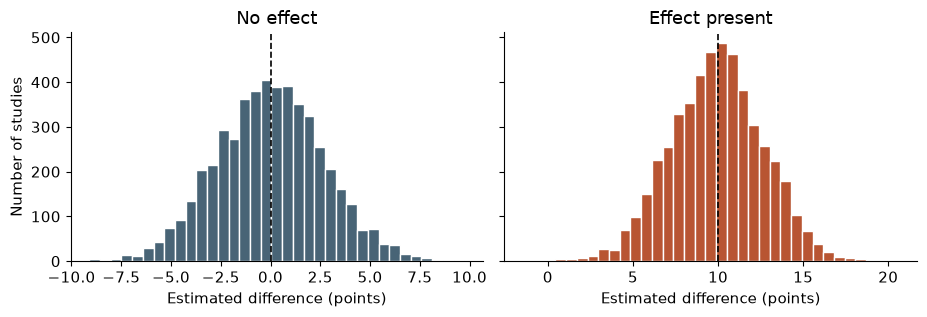

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.3), sharey=True)
for ax, (label, runs, effect, color) in zip(axes, [
        ('No effect', null_runs, 0, '#486476'), ('Effect present', effect_runs, 10, '#b85532')]):
    ax.hist(runs['difference'], bins=35, color=color, edgecolor='white')
    ax.axvline(effect, color='black', linestyle='--', linewidth=1.2)
    ax.set(title=label, xlabel='Estimated difference (points)')
axes[0].set_ylabel('Number of studies')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'report_effects.png', dpi=220)
plt.show()

기본 설정에서 제1종 오류율은 4.66%, 제2종 오류율은 5.00%, 검정력은 95.00%입니다.
효과 추정치 평균은 H0에서 −0.01점, H1에서 9.92점이고 연구 간 SD는 약 2.7점입니다.
참가자가 많으면 효과 추정의 변동과 신뢰구간 폭이 줄고 검정력이 높아질 것으로 예상합니다.
효과가 작거나 점수의 개인차가 크면 효과를 발견하기 어렵습니다.
반복 횟수를 늘리는 것은 오류율 추정의 안정성을 높이지만, 개별 연구의 정밀도를 높이지는 않습니다.
이는 가정한 모형의 분석 성능이며 실제 음악 맞춤 효과를 입증하는 결과는 아닙니다.
위 수치 해설은 보고서와 같은 기본 설정 기준입니다. 모수·seed를 바꾸면 다시 해석해야 합니다.